In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import string
import random

# Automatically use GPU if available (highly recommended)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running on device: {device}")

Running on device: cpu


In [ ]:
CHARS = string.ascii_uppercase + string.digits + "_-!@"

class MultimodalCryptoDataset(Dataset):
    def __init__(self, train=True, max_samples=5000, seq_len=16, key_dim=16):
        self.seq_len = seq_len
        self.key_dim = key_dim

        transform = transforms.Compose([
            transforms.ToTensor() # Scales pixels to [0.0, 1.0], shape [3, 32, 32]
        ])
        self.cifar = torchvision.datasets.CIFAR10(
            root='./data', train=train, download=True, transform=transform
        )
        # Subset for fast training in Colab (increase to 50000 for full training)
        self.max_samples = min(max_samples, len(self.cifar))

    def __len__(self):
        return self.max_samples

    def __getitem__(self, idx):
        img, _ = self.cifar[idx]

        # Generate a random 16-character confidential message
        msg_str = "".join(random.choices(CHARS, k=self.seq_len))
        text_tokens = torch.tensor([ord(c) for c in msg_str], dtype=torch.long)

        # Generate a random 16-D secret key and a mismatched wrong key
        correct_key = torch.randn(self.key_dim)
        wrong_key = torch.randn(self.key_dim)

        return img, text_tokens, correct_key, wrong_key

# Create DataLoaders
train_dataset = MultimodalCryptoDataset(train=True, max_samples=5000)
test_dataset = MultimodalCryptoDataset(train=False, max_samples=500)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=True)

print(f"Loaded {len(train_dataset)} training samples and {len(test_dataset)} test samples.")

100%|██████████| 170M/170M [40:17<00:00, 70.5kB/s]


Loaded 5000 training samples and 500 test samples.


In [ ]:
class MultimodalNeuralCrypto(nn.Module):
    def __init__(self, vocab_size=128, text_seq_len=16, embed_dim=64, key_dim=16):
        super(MultimodalNeuralCrypto, self).__init__()
        self.text_seq_len = text_seq_len
        self.embed_dim = embed_dim

        # ==========================================
        # ALICE (ENCRYPTION / ENCODER)
        # ==========================================
        # 1. CNN for Image Feature Extraction (3x32x32 -> 64x4x4)
        self.img_encoder = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, embed_dim, kernel_size=4, stride=2, padding=1),
            nn.ReLU()
        )

        # 2. GRU for Text Sequence & Key Conditioning
        self.text_embedding = nn.Embedding(vocab_size, embed_dim)
        self.text_rnn_encoder = nn.GRU(embed_dim, embed_dim, batch_first=True)
        self.key_projector = nn.Linear(key_dim, embed_dim)

        # 3. Transformer for Global Multimodal Scrambling
        enc_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=4, dim_feedforward=128, batch_first=True
        )
        self.transformer_scrambler = nn.TransformerEncoder(enc_layer, num_layers=2)

        # ==========================================
        # BOB (DECRYPTION / DECODER)
        # ==========================================
        # 1. Transformer for Descrambling
        dec_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=4, dim_feedforward=128, batch_first=True
        )
        self.transformer_descrambler = nn.TransformerEncoder(dec_layer, num_layers=2)

        # 2. GRU for Text Reconstruction
        self.text_rnn_decoder = nn.GRU(embed_dim, embed_dim, batch_first=True)
        self.text_out = nn.Linear(embed_dim, vocab_size)

        # 3. CNN (ConvTranspose2d) for Image Reconstruction (64x4x4 -> 3x32x32)
        self.img_decoder = nn.Sequential(
            nn.ConvTranspose2d(embed_dim, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def encrypt(self, img, text_tokens, secret_key):
        b = img.size(0)
        # Image -> 16 spatial tokens
        img_feats = self.img_encoder(img)
        img_tokens = img_feats.view(b, self.embed_dim, -1).permute(0, 2, 1)

        # Text + Key -> 16 sequential tokens
        key_emb = self.key_projector(secret_key).unsqueeze(0) # [1, B, 64]
        txt_emb = self.text_embedding(text_tokens)
        txt_tokens, _ = self.text_rnn_encoder(txt_emb, key_emb)

        # Fuse [16 img + 16 text + 1 key] = 33 tokens & Scramble
        combined = torch.cat([img_tokens, txt_tokens, key_emb.permute(1, 0, 2)], dim=1)
        cipher_tensor = self.transformer_scrambler(combined)
        return cipher_tensor

    def decrypt(self, cipher_tensor, secret_key):
        b = cipher_tensor.size(0)
        # Unlock cipher with receiver's key
        key_emb = self.key_projector(secret_key).unsqueeze(1) # [B, 1, 64]
        unlocked = cipher_tensor + key_emb

        # Descramble globally
        descrambled = self.transformer_descrambler(unlocked)
        img_tokens = descrambled[:, :16, :]
        txt_tokens = descrambled[:, 16:16 + self.text_seq_len, :]

        # Reconstruct Image
        img_feats = img_tokens.permute(0, 2, 1).view(b, self.embed_dim, 4, 4)
        rec_img = self.img_decoder(img_feats)

        # Reconstruct Text
        rnn_out, _ = self.text_rnn_decoder(txt_tokens, key_emb.permute(1, 0, 2))
        rec_text_logits = self.text_out(rnn_out)
        return rec_img, rec_text_logits

model = MultimodalNeuralCrypto().to(device)
print(f"Total Trainable Parameters: {sum(p.numel() for p in model.parameters()):,}")

Total Trainable Parameters: 401,347


In [ ]:
optimizer = optim.Adam(model.parameters(), lr=2e-3)
img_criterion = nn.MSELoss()
text_criterion = nn.CrossEntropyLoss()

EPOCHS = 15
history = {"img_loss": [], "txt_acc": []}

print("Starting training...")
for epoch in range(1, EPOCHS + 1):
    model.train()
    total_img_loss = 0.0
    total_txt_correct = 0
    total_chars = 0

    for imgs, texts, keys, wrong_keys in train_loader:
        imgs, texts = imgs.to(device), texts.to(device)
        keys, wrong_keys = keys.to(device), wrong_keys.to(device)

        optimizer.zero_grad()

        # 1. Encrypt with Alice
        cipher = model.encrypt(imgs, texts, keys)

        # 2. Decrypt with Bob (Correct Key)
        rec_imgs, rec_txt_logits = model.decrypt(cipher, keys)
        loss_img = img_criterion(rec_imgs, imgs)
        loss_txt = text_criterion(rec_txt_logits.view(-1, 128), texts.view(-1))

        # 3. Security Penalty (Wrong Key must fail to reconstruct image)
        wrong_imgs, _ = model.decrypt(cipher, wrong_keys)
        security_loss = torch.relu(0.15 - img_criterion(wrong_imgs, imgs))

        # Weighted Total Loss
        loss = (5.0 * loss_img) + (1.5 * loss_txt) + (2.0 * security_loss)
        loss.backward()
        optimizer.step()

        # Track metrics
        total_img_loss += loss_img.item()
        preds = rec_txt_logits.argmax(dim=-1)
        total_txt_correct += (preds == texts).sum().item()
        total_chars += texts.numel()

    avg_img_loss = total_img_loss / len(train_loader)
    txt_acc = (total_txt_correct / total_chars) * 100
    history["img_loss"].append(avg_img_loss)
    history["txt_acc"].append(txt_acc)
    print(f"Epoch [{epoch:02d}/{EPOCHS}] | Image MSE: {avg_img_loss:.4f} | Text Accuracy: {txt_acc:.2f}%")


Starting training...
Epoch [01/15] | Image MSE: 0.0499 | Text Accuracy: 80.66%
Epoch [02/15] | Image MSE: 0.0246 | Text Accuracy: 100.00%
Epoch [03/15] | Image MSE: 0.0363 | Text Accuracy: 100.00%
Epoch [04/15] | Image MSE: 0.0174 | Text Accuracy: 100.00%
Epoch [05/15] | Image MSE: 0.0161 | Text Accuracy: 100.00%
Epoch [06/15] | Image MSE: 0.0149 | Text Accuracy: 100.00%
Epoch [07/15] | Image MSE: 0.0122 | Text Accuracy: 100.00%
Epoch [08/15] | Image MSE: 0.0107 | Text Accuracy: 100.00%
Epoch [09/15] | Image MSE: 0.0148 | Text Accuracy: 100.00%
Epoch [10/15] | Image MSE: 0.0152 | Text Accuracy: 100.00%
Epoch [11/15] | Image MSE: 0.0164 | Text Accuracy: 99.99%
Epoch [12/15] | Image MSE: 0.0103 | Text Accuracy: 100.00%
Epoch [13/15] | Image MSE: 0.0087 | Text Accuracy: 100.00%
Epoch [14/15] | Image MSE: 0.0107 | Text Accuracy: 100.00%
Epoch [15/15] | Image MSE: 0.0080 | Text Accuracy: 100.00%


In [ ]:
torch.save(model.state_dict(), "multimodal_neural_crypto.pth")
print("Model weights saved successfully to multimodal_neural_crypto.pth")

Model weights saved successfully to multimodal_neural_crypto.pth


Original Message      : !9!H@-UPSM098XNF
Decrypted (Right Key) : !9!H@-UPSM098XNF
Decrypted (Wrong Key) : !9!H@-UPSM098XNF


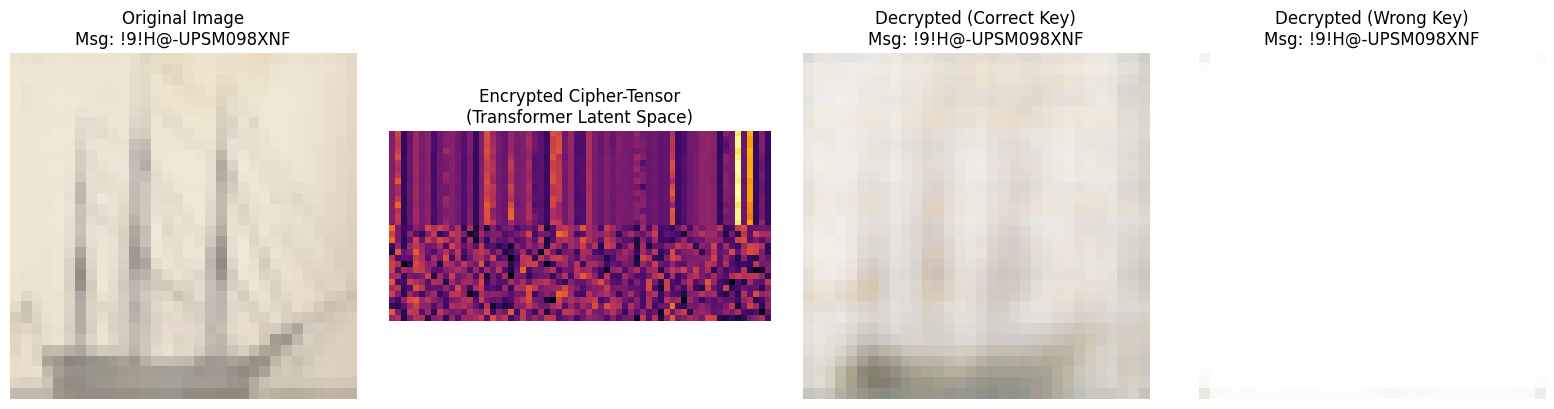

In [ ]:
def tokens_to_str(token_tensor):
    return "".join(chr(max(32, min(int(c), 126))) for c in token_tensor.cpu().tolist())

def cipher_to_heatmap(cipher_tensor):
    flat = cipher_tensor.detach().cpu().numpy().flatten()
    norm = (flat - flat.min()) / (flat.max() - flat.min() + 1e-8)
    return norm[:2048].reshape(32, 64)

model.eval()
imgs, texts, keys, wrong_keys = next(iter(test_loader))
imgs, texts = imgs.to(device), texts.to(device)
keys, wrong_keys = keys.to(device), wrong_keys.to(device)

with torch.no_grad():
    cipher = model.encrypt(imgs, texts, keys)
    rec_imgs, rec_txt_logits = model.decrypt(cipher, keys)
    wrong_imgs, wrong_txt_logits = model.decrypt(cipher, wrong_keys)

# Pick the first sample in the test batch to visualize
idx = 0
orig_msg = tokens_to_str(texts[idx])
good_msg = tokens_to_str(rec_txt_logits[idx].argmax(dim=-1))
bad_msg  = tokens_to_str(wrong_txt_logits[idx].argmax(dim=-1))

print(f"Original Message      : {orig_msg}")
print(f"Decrypted (Right Key) : {good_msg}")
print(f"Decrypted (Wrong Key) : {bad_msg}")

# Plot 4-panel visual comparison
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(imgs[idx].cpu().permute(1, 2, 0).numpy())
axes[0].set_title(f"Original Image\nMsg: {orig_msg}")
axes[0].axis("off")

axes[1].imshow(cipher_to_heatmap(cipher[idx]), cmap="inferno")
axes[1].set_title("Encrypted Cipher-Tensor\n(Transformer Latent Space)")
axes[1].axis("off")

axes[2].imshow(rec_imgs[idx].cpu().permute(1, 2, 0).numpy())
axes[2].set_title(f"Decrypted (Correct Key)\nMsg: {good_msg}")
axes[2].axis("off")

axes[3].imshow(wrong_imgs[idx].cpu().permute(1, 2, 0).numpy())
axes[3].set_title(f"Decrypted (Wrong Key)\nMsg: {bad_msg}")
axes[3].axis("off")

plt.tight_layout()
plt.show()